In [1]:
# Install the required libraries
!pip -q install scikit-learn pandas numpy matplotlib seaborn

# Import libraries
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
categories = [
    "comp.graphics",
    "rec.sport.baseball",
    "sci.med",
    "talk.politics.misc"
]

dataset = fetch_20newsgroups(
    subset="all",
    categories=categories,
    remove=("headers", "footers", "quotes")
)

df = pd.DataFrame({
    "text": dataset.data,
    "label": dataset.target
})

df["category"] = df["label"].map(
    dict(enumerate(dataset.target_names))
)

# Remove empty documents
df["text"] = df["text"].fillna("").astype(str)
df = df[df["text"].str.strip() != ""].reset_index(drop=True)

print("Dataset loaded successfully!")
print("Total documents:", len(df))
print("Number of classes:", df["category"].nunique())
print("\nFirst five records:")
print(df[["text", "category"]].head())

print("\nClass distribution:")
print(df["category"].value_counts())

Dataset loaded successfully!
Total documents: 3629
Number of classes: 4

First five records:
                                                text            category
0  \nI guess I'm still not clear on what the term...             sci.med
1  Could someone give me some information on the ...             sci.med
2                   sandiego and graig nettles\n\n\n  rec.sport.baseball
3  Hi there\n\nI am very interested in Rayshade 4...       comp.graphics
4  Here is a press release from the Natural Resou...             sci.med

Class distribution:
category
sci.med               960
rec.sport.baseball    958
comp.graphics         955
talk.politics.misc    756
Name: count, dtype: int64


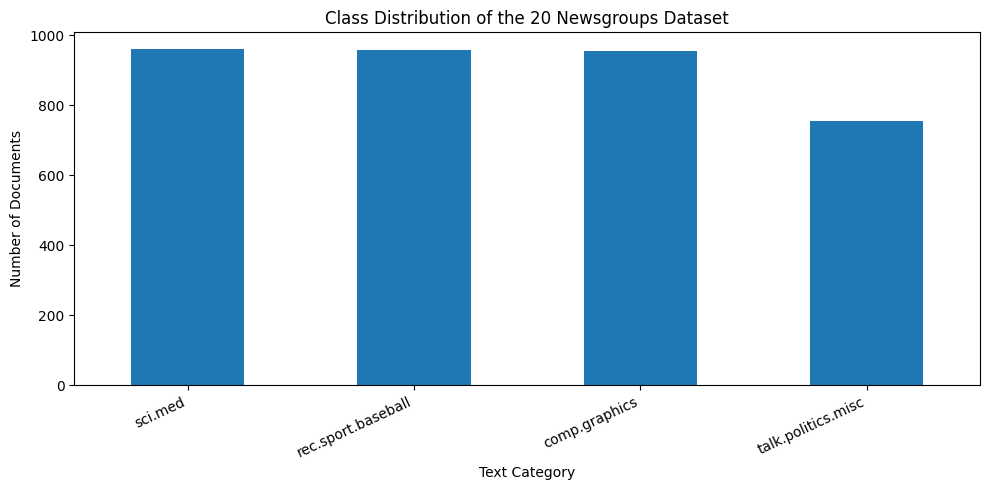

In [3]:
class_counts = df["category"].value_counts()

plt.figure(figsize=(10, 5))
class_counts.plot(kind="bar")
plt.title("Class Distribution of the 20 Newsgroups Dataset")
plt.xlabel("Text Category")
plt.ylabel("Number of Documents")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [4]:
X = df["text"]
y = df["label"]

# Use the same split for all four models
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Convert text into numerical TF-IDF features
vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training documents:", X_train_tfidf.shape[0])
print("Testing documents:", X_test_tfidf.shape[0])
print("Number of TF-IDF features:", X_train_tfidf.shape[1])
print("Training and testing split completed!")

Training documents: 2903
Testing documents: 726
Number of TF-IDF features: 5000
Training and testing split completed!


In [5]:
models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        metric="cosine",
        algorithm="brute"
    ),

    "SVM": LinearSVC(
        C=1.0,
        random_state=42,
        max_iter=5000
    ),

    "Naive Bayes": MultinomialNB(
        alpha=1.0
    )
}

print("Four classifiers created:")
for name in models:
    print("-", name)

Four classifiers created:
- Decision Tree
- KNN
- SVM
- Naive Bayes


In [6]:
results = []
predictions = {}

for name, model in models.items():
    # Measure training time
    start_train = time.perf_counter()
    model.fit(X_train_tfidf, y_train)
    train_time = time.perf_counter() - start_train

    # Measure prediction time
    start_predict = time.perf_counter()
    y_pred = model.predict(X_test_tfidf)
    predict_time = time.perf_counter() - start_predict

    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Training Time (sec)": train_time,
        "Prediction Time (sec)": predict_time
    })

results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
display(results_df.round(4))

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,Training Time (sec),Prediction Time (sec)
0,Decision Tree,0.7534,0.7538,0.7534,0.7526,1.4403,0.0018
1,KNN,0.8815,0.8860,0.8815,0.8813,0.0022,0.1288
2,SVM,0.9201,0.9205,0.9201,0.9198,0.0692,0.0009
3,Naive Bayes,0.9105,0.9107,0.9105,0.9100,0.0048,0.0008


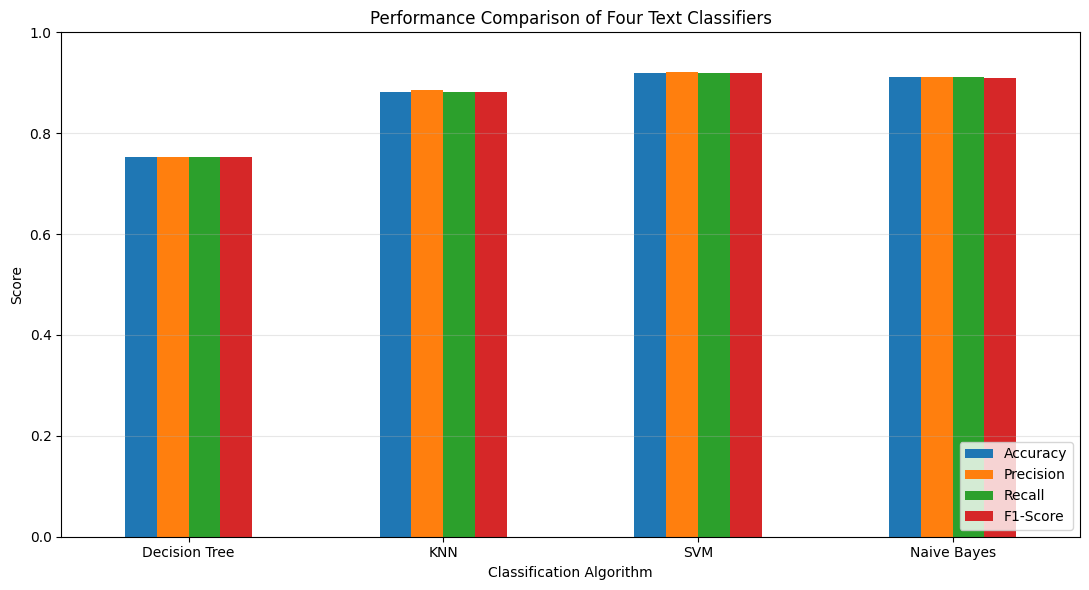

In [7]:
metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

plot_df = results_df.set_index("Model")[metric_columns]

plot_df.plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1)
)

plt.title("Performance Comparison of Four Text Classifiers")
plt.xlabel("Classification Algorithm")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

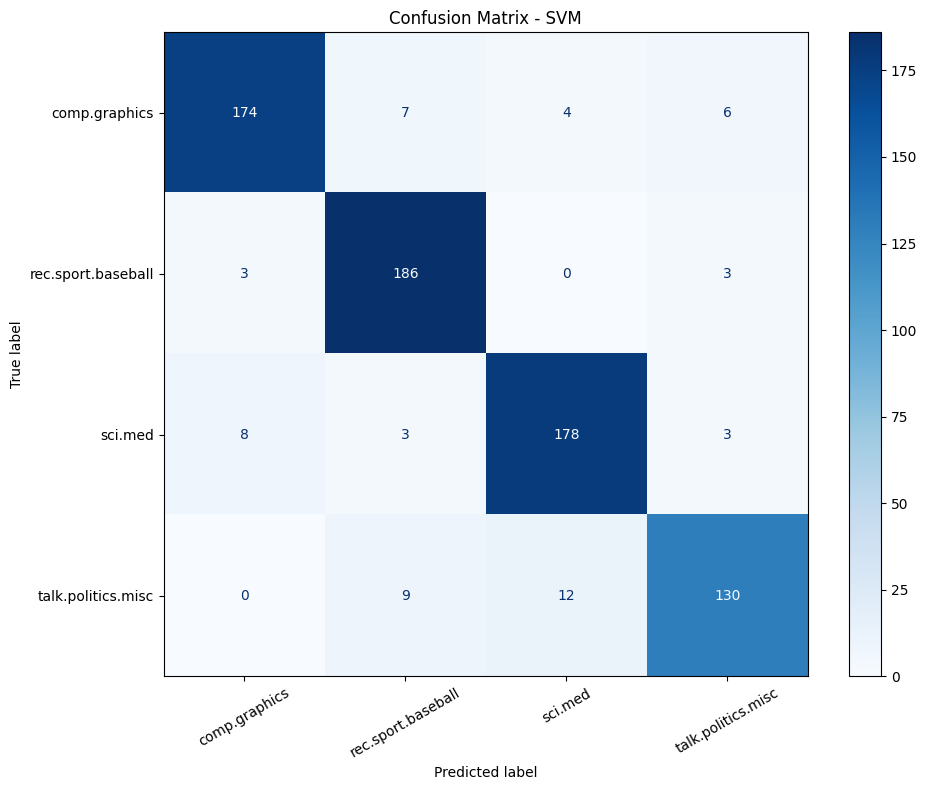

Best model based on weighted F1-score: SVM

Classification report:
                    precision    recall  f1-score   support

     comp.graphics       0.94      0.91      0.93       191
rec.sport.baseball       0.91      0.97      0.94       192
           sci.med       0.92      0.93      0.92       192
talk.politics.misc       0.92      0.86      0.89       151

          accuracy                           0.92       726
         macro avg       0.92      0.92      0.92       726
      weighted avg       0.92      0.92      0.92       726



In [8]:
best_model_name = results_df.loc[
    results_df["F1-Score"].idxmax(), "Model"
]

best_predictions = predictions[best_model_name]

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=np.arange(len(dataset.target_names))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=dataset.target_names
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=30)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

print("Best model based on weighted F1-score:", best_model_name)
print("\nClassification report:")
print(
    classification_report(
        y_test,
        best_predictions,
        labels=np.arange(len(dataset.target_names)),
        target_names=dataset.target_names,
        zero_division=0
    )
)

SVM WHAT-IF ANALYSIS


,SVM C Value,Accuracy,Precision,Recall,F1-Score
0,0.1,0.9201,0.9202,0.9201,0.9197
1,1.0,0.9201,0.9205,0.9201,0.9198


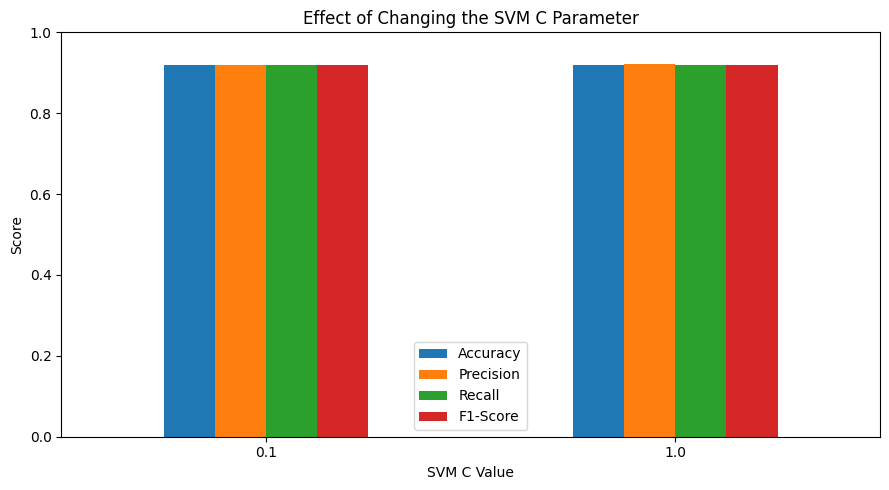

In [9]:
svm_what_if_results = []

for c_value in [0.1, 1.0]:
    experiment_model = LinearSVC(
        C=c_value,
        random_state=42,
        max_iter=5000
    )

    experiment_model.fit(X_train_tfidf, y_train)
    experiment_pred = experiment_model.predict(X_test_tfidf)

    svm_what_if_results.append({
        "SVM C Value": c_value,
        "Accuracy": accuracy_score(y_test, experiment_pred),
        "Precision": precision_score(
            y_test, experiment_pred,
            average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, experiment_pred,
            average="weighted", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, experiment_pred,
            average="weighted", zero_division=0
        )
    })

what_if_df = pd.DataFrame(svm_what_if_results)

print("SVM WHAT-IF ANALYSIS")
display(what_if_df.round(4))

what_if_df.set_index("SVM C Value")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(kind="bar", figsize=(9, 5), ylim=(0, 1))

plt.title("Effect of Changing the SVM C Parameter")
plt.xlabel("SVM C Value")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [10]:
# Save experimental results
results_df.to_csv("model_comparison.csv", index=False)
what_if_df.to_csv("svm_what_if_results.csv", index=False)

cm_df = pd.DataFrame(
    cm,
    index=dataset.target_names,
    columns=dataset.target_names
)
cm_df.to_csv("best_model_confusion_matrix.csv")

# Save the performance graph
plt.figure(figsize=(11, 6))
results_df.set_index("Model")[metric_columns].plot(
    kind="bar", ylim=(0, 1), ax=plt.gca()
)
plt.title("Text Classifier Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=300, bbox_inches="tight")
plt.close()

print("Saved files:")
print("- model_comparison.csv")
print("- svm_what_if_results.csv")
print("- best_model_confusion_matrix.csv")
print("- model_comparison.png")

Saved files:
- model_comparison.csv
- svm_what_if_results.csv
- best_model_confusion_matrix.csv
- model_comparison.png


In [11]:
from google.colab import files

for filename in [
    "model_comparison.csv",
    "svm_what_if_results.csv",
    "best_model_confusion_matrix.csv",
    "model_comparison.png"
]:
    files.download(filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>